In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## grouped-bar-chart

**Figure 1: Accuracy of four training methods on GSM8K, MATH and HumanEval.** Ours is best on every benchmark, ahead of the strongest baseline, DPO, by 3.6, 4.3 and 2.9 points.

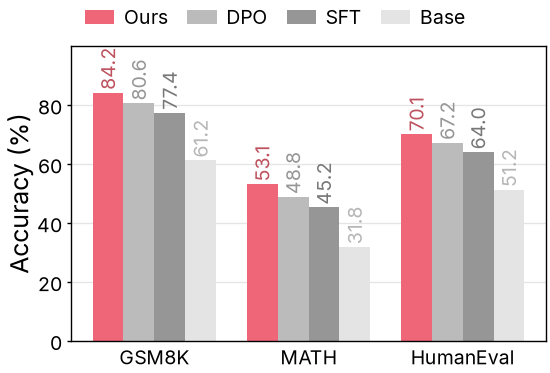

In [2]:
with open("../data/grouped-bar-chart.json") as f:
    data = json.load(f)

benchmarks = data["benchmarks"]
methods = ["Ours", "DPO", "SFT", "Base"]
method_colors = {"Ours": colors["ours"], "DPO": colors["neutral"], "SFT": darken(colors["neutral"]), "Base": lighten(colors["neutral"])}

fig, ax = plt.subplots(figsize=(2.75, 2))
x = np.arange(len(benchmarks))
width = 0.8 / len(methods)
for i, method in enumerate(methods):
    accuracy = [100 * score for score in data["scores"][method]]
    bars = ax.bar(x + (i - (len(methods) - 1) / 2) * width, accuracy, width, color=method_colors[method], linewidth=0, label=method)
    # vertical labels: twelve side-by-side labels overlap when written horizontally at half text width
    ax.bar_label(bars, fmt="%.1f", color=darken(method_colors[method]), rotation=90, padding=1)
ax.set_xticks(x, labels=benchmarks)
ax.tick_params(axis="x", length=0)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Accuracy (%)")
fig.legend(loc="outside upper center", ncol=len(methods), frameon=False, borderaxespad=0)

fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/grouped-bar-chart.pdf")
fig.savefig("../outputs/grouped-bar-chart.png")
plt.show()